In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob

# Find the file path automatically
print(glob.glob('/kaggle/input/**/Listings.csv', recursive=True))

# Load it
df = pd.read_csv('/kaggle/input/datasets/blessinglandelani/listings-csv/Listings.csv',encoding='latin1')
print(f"Shape: {df.shape}")
print(df.head())
print(df.columns.tolist())

['/kaggle/input/datasets/blessinglandelani/listings-csv/Listings.csv']


/tmp/ipykernel_50/3054197340.py:11: DtypeWarning: Columns (5,13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/kaggle/input/datasets/blessinglandelani/listings-csv/Listings.csv',encoding='latin1')


Shape: (279712, 33)
   listing_id                                              name   host_id  \
0      281420    Beautiful Flat in le Village Montmartre, Paris   1466919   
1     3705183                   39 mÃÂ² Paris (Sacre CÃâur)  10328771   
2     4082273               Lovely apartment with Terrace, 60m2  19252768   
3     4797344               Cosy studio (close to Eiffel tower)  10668311   
4     4823489  Close to Eiffel Tower - Beautiful flat : 2 rooms  24837558   

   host_since                 host_location host_response_time  \
0  2011-12-03  Paris, Ile-de-France, France                NaN   
1  2013-11-29  Paris, Ile-de-France, France                NaN   
2  2014-07-31  Paris, Ile-de-France, France                NaN   
3  2013-12-17  Paris, Ile-de-France, France                NaN   
4  2014-12-14  Paris, Ile-de-France, France                NaN   

   host_response_rate  host_acceptance_rate host_is_superhost  \
0                 NaN                   NaN            

In [4]:
# Cell 2 - Quick look at the data
print("Columns:")
for i, col in enumerate(df.columns):
    print(f"{i}: {col}")

print("\n--- Missing values (top 15) ---")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\n--- Data types ---")
print(df.dtypes)

Columns:
0: listing_id
1: name
2: host_id
3: host_since
4: host_location
5: host_response_time
6: host_response_rate
7: host_acceptance_rate
8: host_is_superhost
9: host_total_listings_count
10: host_has_profile_pic
11: host_identity_verified
12: neighbourhood
13: district
14: city
15: latitude
16: longitude
17: property_type
18: room_type
19: accommodates
20: bedrooms
21: amenities
22: price
23: minimum_nights
24: maximum_nights
25: review_scores_rating
26: review_scores_accuracy
27: review_scores_cleanliness
28: review_scores_checkin
29: review_scores_communication
30: review_scores_location
31: review_scores_value
32: instant_bookable

--- Missing values (top 15) ---
district                       242700
host_response_time             128782
host_response_rate             128782
host_acceptance_rate           113087
review_scores_value             91785
review_scores_location          91775
review_scores_checkin           91771
review_scores_accuracy          91713
review_scores_com

In [5]:
# Cell 3 - Look at price
print(df['price'].head(10))
print("\nPrice dtype:", df['price'].dtype)
print("\nPrice describe:")
print(df['price'].describe())
print("\nNeighbourhoods:")
print(df['neighbourhood'].value_counts().head(10))

0     53
1    120
2     89
3     58
4     60
5     95
6     80
7     59
8     80
9     90
Name: price, dtype: int64

Price dtype: int64

Price describe:
count    279712.000000
mean        608.792737
std        3441.826611
min           0.000000
25%          75.000000
50%         150.000000
75%         474.000000
max      625216.000000
Name: price, dtype: float64

Neighbourhoods:
neighbourhood
I Centro Storico     14874
Sydney                8074
Copacabana            7712
Cuauhtemoc            7626
Buttes-Montmartre     7237
Beyoglu               6674
Popincourt            6206
Vaugirard             4826
Waverley              4737
Enclos-St-Laurent     4628
Name: count, dtype: int64


In [6]:
# Cell 4 - Check if this is really global
print("Latitude range:", df['latitude'].min(), "to", df['latitude'].max())
print("Longitude range:", df['longitude'].min(), "to", df['longitude'].max())
print("\nTotal unique neighbourhoods:", df['neighbourhood'].nunique())

# Filter to Paris area using lat/lon
paris = df[(df['latitude'] > 48.8) & (df['latitude'] < 48.92) & 
           (df['longitude'] > 2.2) & (df['longitude'] < 2.5)].copy()
print(f"\nParis listings: {len(paris)} out of {len(df)}")
print("\nParis neighbourhoods top 10:")
print(paris['neighbourhood'].value_counts().head(10))
print("\nParis median price:", paris['price'].median())

Latitude range: -34.2644 to 48.90491
Longitude range: -99.33963 to 151.33981

Total unique neighbourhoods: 660

Paris listings: 64690 out of 279712

Paris neighbourhoods top 10:
neighbourhood
Buttes-Montmartre      7237
Popincourt             6206
Vaugirard              4826
Enclos-St-Laurent      4628
Batignolles-Monceau    4330
Menilmontant           3758
Buttes-Chaumont        3728
Passy                  3215
Opera                  3157
Temple                 2943
Name: count, dtype: int64

Paris median price: 80.0


In [7]:
# Cell 5 - Clean Paris data and analyse
paris = df[(df['latitude'] > 48.8) & (df['latitude'] < 48.92) & 
           (df['longitude'] > 2.2) & (df['longitude'] < 2.5)].copy()

# Clean price: remove 0 and crazy outliers
paris_clean = paris[(paris['price'] > 10) & (paris['price'] <= 1000)].copy()
print(f"Paris before cleaning: {len(paris)}")
print(f"Paris after cleaning: {len(paris_clean)}")
print(f"Median: ${paris_clean['price'].median():.0f} | Mean: ${paris_clean['price'].mean():.0f}")

print("\n--- Median price by ROOM TYPE ---")
print(paris_clean.groupby('room_type')['price'].median().sort_values(ascending=False))

print("\n--- Median price by NEIGHBOURHOOD (top 10 most expensive) ---")
print(paris_clean.groupby('neighbourhood')['price'].median().sort_values(ascending=False).head(10))

print("\n--- Median price by ACCOMMODATES ---")
print(paris_clean.groupby('accommodates')['price'].median().head(8))

Paris before cleaning: 64690
Paris after cleaning: 64410
Median: $80 | Mean: $106

--- Median price by ROOM TYPE ---
room_type
Hotel room      160.0
Entire place     82.0
Private room     53.0
Shared room      34.0
Name: price, dtype: float64

--- Median price by NEIGHBOURHOOD (top 10 most expensive) ---
neighbourhood
Elysee            125.0
Louvre            115.0
Hotel-de-Ville    109.0
Luxembourg        107.0
Temple            100.0
Palais-Bourbon    100.0
Bourse            100.0
Passy              99.0
Pantheon           95.0
Opera              90.0
Name: price, dtype: float64

--- Median price by ACCOMMODATES ---
accommodates
1     45.0
2     69.0
3     80.0
4     99.0
5    130.0
6    165.0
7    200.0
8    249.0
Name: price, dtype: float64


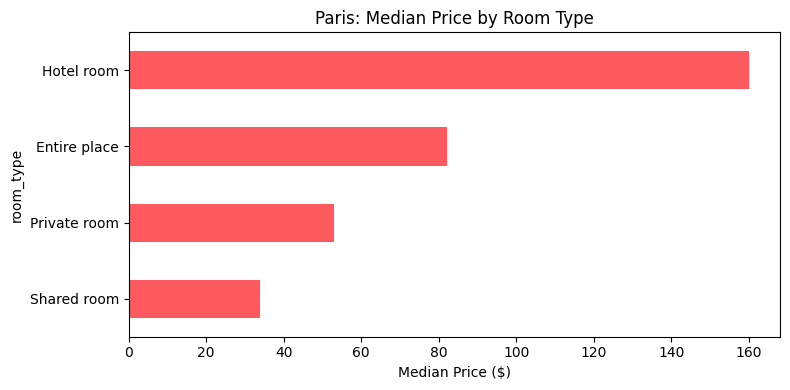

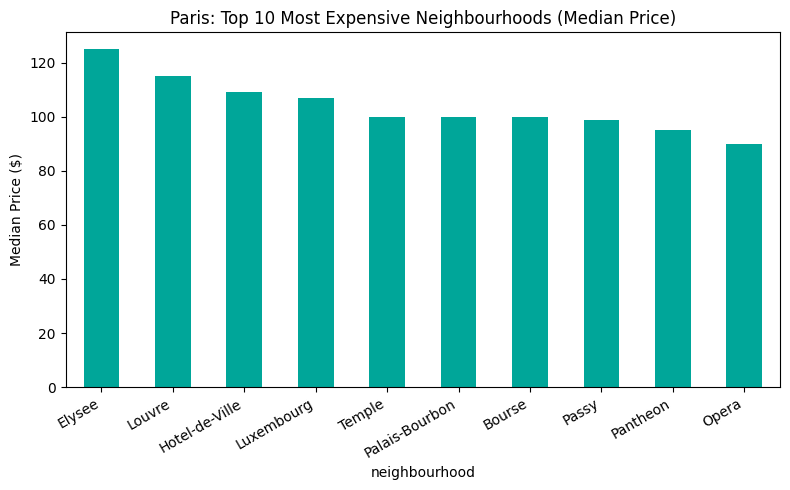

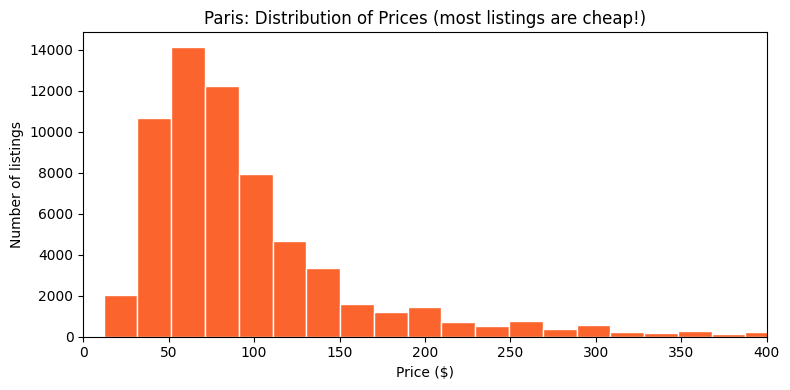

In [8]:
# Cell 6 - Charts for report
import matplotlib.pyplot as plt

# Chart 1: Price by room type
plt.figure(figsize=(8,4))
paris_clean.groupby('room_type')['price'].median().sort_values().plot(kind='barh', color='#FF5A5F')
plt.title('Paris: Median Price by Room Type')
plt.xlabel('Median Price ($)')
plt.tight_layout()
plt.show()

# Chart 2: Top 10 most expensive neighbourhoods
plt.figure(figsize=(8,5))
paris_clean.groupby('neighbourhood')['price'].median().sort_values(ascending=False).head(10).plot(kind='bar', color='#00A699')
plt.title('Paris: Top 10 Most Expensive Neighbourhoods (Median Price)')
plt.ylabel('Median Price ($)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

# Chart 3: Price distribution
plt.figure(figsize=(8,4))
plt.hist(paris_clean['price'], bins=50, color='#FC642D', edgecolor='white')
plt.title('Paris: Distribution of Prices (most listings are cheap!)')
plt.xlabel('Price ($)')
plt.ylabel('Number of listings')
plt.xlim(0, 400)
plt.tight_layout()
plt.show()

In [9]:
# Cell 7 - What else drives price?
print("--- Median price by PROPERTY TYPE (top 8) ---")
print(paris_clean.groupby('property_type')['price'].median().sort_values(ascending=False).head(8))

print("\n--- Median price: Superhost vs Not ---")
print(paris_clean.groupby('host_is_superhost')['price'].median())

print("\n--- Median price by ACCOMMODATES ---")
print(paris_clean.groupby('accommodates')['price'].median().head(8))

print("\n--- Correlation with price ---")
print(paris_clean[['price','accommodates','bedrooms','review_scores_rating','minimum_nights']].corr()['price'].sort_values(ascending=False))

print("\n--- How many of each room type? ---")
print(paris_clean['room_type'].value_counts())
print("\n--- How many Superhosts? ---")
print(paris_clean['host_is_superhost'].value_counts())

--- Median price by PROPERTY TYPE (top 8) ---
property_type
Shared room in boutique hotel    800.0
Private room in chalet           500.0
Shared room in igloo             500.0
Shared room in cabin             400.0
Treehouse                        380.0
Entire floor                     380.0
Houseboat                        340.0
Entire cottage                   324.5
Name: price, dtype: float64

--- Median price: Superhost vs Not ---
host_is_superhost
f    80.0
t    92.0
Name: price, dtype: float64

--- Median price by ACCOMMODATES ---
accommodates
1     45.0
2     69.0
3     80.0
4     99.0
5    130.0
6    165.0
7    200.0
8    249.0
Name: price, dtype: float64

--- Correlation with price ---
price                   1.000000
accommodates            0.501110
bedrooms                0.360567
review_scores_rating    0.046295
minimum_nights         -0.003842
Name: price, dtype: float64

--- How many of each room type? ---
room_type
Entire place    55213
Private room     7462
Hotel room 